# NYC Green Taxi: Trip Duration Baseline

**Goal:** predict trip duration (minutes) from pickup and dropoff zone, distance and pickup time.
**Train:** January 2025 | **Validate:** February 2025 | **Metric:** RMSE (lower is better)

Plan: load and clean data, set a naive baseline, train a few simple models, compare them on validation data, inspect errors, save the best model.

In [1]:
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

sns.set_theme(style="whitegrid")

DATA_DIR = Path("../data")
TRAIN_FILE = DATA_DIR / "green_tripdata_2025-01.parquet"
VAL_FILE = DATA_DIR / "green_tripdata_2025-02.parquet"
MODEL_DIR = Path("../models")

## 1. Load and clean

Cleaning rules:
- keep trips lasting **1 to 60 minutes** (negative, zero and multi-hour trips are mostly errors)
- keep trips with a **distance above 0 and up to 50 miles**

Features:
- `PULocationID`, `DOLocationID`: pickup and dropoff zones, treated as **categories** (strings)
- `PU_DO`: the pickup and dropoff pair, since a specific route has its own typical duration
- `pickup_hour`, `pickup_weekday`: rush hour and weekday effects, also categories
- `trip_distance`: numeric

In [2]:
CATEGORICAL = ["PULocationID", "DOLocationID", "PU_DO", "pickup_hour", "pickup_weekday"]
NUMERICAL = ["trip_distance"]
TARGET = "duration"


def read_df(path, min_minutes=1, max_minutes=60, max_miles=50):
    df = pd.read_parquet(path)
    n_raw = len(df)

    pickup = pd.to_datetime(df["lpep_pickup_datetime"])
    dropoff = pd.to_datetime(df["lpep_dropoff_datetime"])
    df[TARGET] = (dropoff - pickup).dt.total_seconds() / 60

    keep = df[TARGET].between(min_minutes, max_minutes) & df["trip_distance"].between(0.01, max_miles)
    df = df[keep].copy()
    pickup = pickup[keep]

    df["PULocationID"] = df["PULocationID"].astype(str)
    df["DOLocationID"] = df["DOLocationID"].astype(str)
    df["PU_DO"] = df["PULocationID"] + "_" + df["DOLocationID"]
    df["pickup_hour"] = pickup.dt.hour.astype(str)
    df["pickup_weekday"] = pickup.dt.dayofweek.astype(str)

    print(f"{path.name}: {n_raw:,} rows -> kept {len(df):,} ({len(df) / n_raw:.1%}), removed {n_raw - len(df):,}")
    return df


df_train = read_df(TRAIN_FILE)
df_val = read_df(VAL_FILE)

green_tripdata_2025-01.parquet: 48,326 rows -> kept 44,625 (92.3%), removed 3,701
green_tripdata_2025-02.parquet: 46,621 rows -> kept 42,701 (91.6%), removed 3,920


/tmp/ipykernel_2580/676763543.py:22: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["pickup_weekday"] = pickup.dt.dayofweek.astype(str)
/tmp/ipykernel_2580/676763543.py:22: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["pickup_weekday"] = pickup.dt.dayofweek.astype(str)


count    44625.00
mean        13.26
std          8.34
min          1.00
25%          7.52
50%         11.32
75%         16.67
max         60.00
Name: duration, dtype: float64


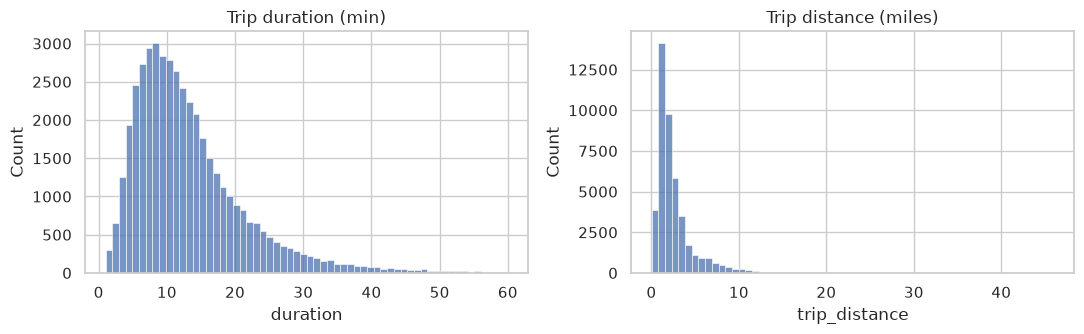

In [3]:
print(df_train[TARGET].describe().round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df_train[TARGET], bins=60, ax=ax[0])
ax[0].set_title("Trip duration (min)")
sns.histplot(df_train["trip_distance"], bins=60, ax=ax[1])
ax[1].set_title("Trip distance (miles)")
plt.tight_layout()

## 2. Vectorize

`DictVectorizer` one-hot encodes the string columns and passes numeric columns through. **Fit on the training data only**, then `transform` validation data so both have identical columns.

In [4]:
dv = DictVectorizer()

train_dicts = df_train[CATEGORICAL + NUMERICAL].to_dict(orient="records")
X_train = dv.fit_transform(train_dicts)

val_dicts = df_val[CATEGORICAL + NUMERICAL].to_dict(orient="records")
X_val = dv.transform(val_dicts)


def to_int32(M):
    # Lasso only accepts sparse matrices with 32-bit indices
    M = M.tocsr().copy()
    M.indices = M.indices.astype(np.int32)
    M.indptr = M.indptr.astype(np.int32)
    return M


X_train, X_val = to_int32(X_train), to_int32(X_val)
y_train = df_train[TARGET].values
y_val = df_val[TARGET].values

print("train:", X_train.shape, "| val:", X_val.shape)
assert X_train.shape[1] == X_val.shape[1], "column mismatch: never fit the vectorizer on validation data"

train: (44625, 3922) | val: (42701, 3922)


## 3. Train and compare

A baseline that predicts the training mean is the bar to beat. Any model must do clearly better on **validation** data, and a big gap between train and validation RMSE signals overfitting.

In [5]:
models = {
    "mean baseline": DummyRegressor(strategy="mean"),
    "linear regression": LinearRegression(),
    "ridge (alpha=1)": Ridge(alpha=1.0),
    "lasso (alpha=0.001)": Lasso(alpha=0.001, max_iter=5000),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred_train, pred_val = model.predict(X_train), model.predict(X_val)
    rows.append({
        "model": name,
        "train_rmse": root_mean_squared_error(y_train, pred_train),
        "val_rmse": root_mean_squared_error(y_val, pred_val),
        "val_mae": mean_absolute_error(y_val, pred_val),
        "val_r2": r2_score(y_val, pred_val),
    })

results = pd.DataFrame(rows).set_index("model").sort_values("val_rmse")
results.round(3)

,train_rmse,val_rmse,val_mae,val_r2
model,,,,
ridge (alpha=1),3.867,4.906,3.028,0.695
lasso (alpha=0.001),4.379,4.978,3.112,0.686
linear regression,3.770,5.045,3.056,0.678
mean baseline,8.341,8.895,6.337,-0.002


In [6]:
best_name = results.drop(index="mean baseline").index[0]
best_model = models[best_name]
y_pred = best_model.predict(X_val)

gain = 1 - results.loc[best_name, "val_rmse"] / results.loc["mean baseline", "val_rmse"]
print(f"Best model: {best_name} | val RMSE {results.loc[best_name, 'val_rmse']:.2f} min "
      f"({gain:.0%} better than the mean baseline)")

Best model: ridge (alpha=1) | val RMSE 4.91 min (45% better than the mean baseline)


## 4. Evaluate the best model

RMSE is one number. These plots show *where* the model is wrong.

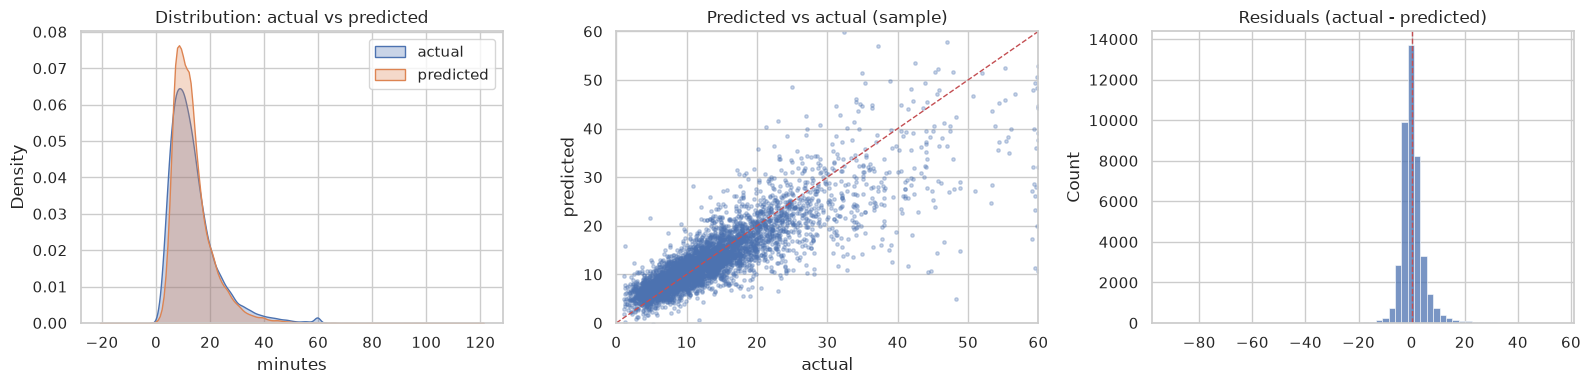

In [7]:
residuals = y_val - y_pred

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sns.kdeplot(y_val, label="actual", ax=ax[0], fill=True, alpha=0.3)
sns.kdeplot(y_pred, label="predicted", ax=ax[0], fill=True, alpha=0.3)
ax[0].set_title("Distribution: actual vs predicted")
ax[0].set_xlabel("minutes")
ax[0].legend()

sample = np.random.default_rng(42).choice(len(y_val), size=min(5000, len(y_val)), replace=False)
ax[1].scatter(y_val[sample], y_pred[sample], s=6, alpha=0.3)
lims = [0, 60]
ax[1].plot(lims, lims, "r--", lw=1)
ax[1].set_xlim(lims); ax[1].set_ylim(lims)
ax[1].set_title("Predicted vs actual (sample)")
ax[1].set_xlabel("actual"); ax[1].set_ylabel("predicted")

sns.histplot(residuals, bins=60, ax=ax[2])
ax[2].axvline(0, color="r", ls="--", lw=1)
ax[2].set_title("Residuals (actual - predicted)")
plt.tight_layout()

               count  mean
distance_band             
<1              6988  2.29
1-2            16105  2.13
2-4            12510  3.14
4-8             5107  4.85
8+              1991  7.52


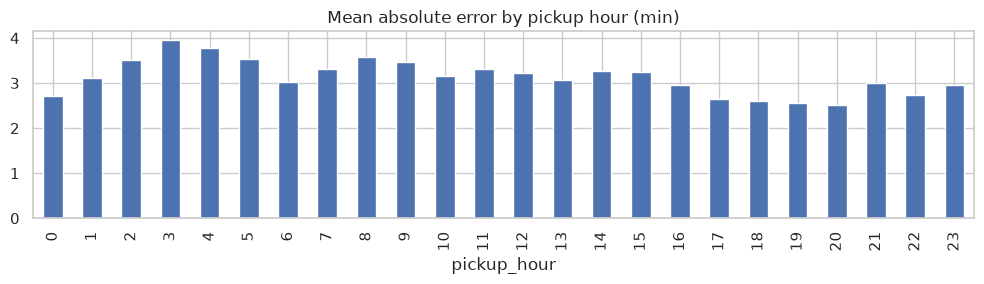

In [8]:
# Where does the model struggle? Error by distance band and by pickup hour.
errors = df_val.assign(pred=y_pred, abs_err=np.abs(residuals))

errors["distance_band"] = pd.cut(errors["trip_distance"], [0, 1, 2, 4, 8, 50],
                                 labels=["<1", "1-2", "2-4", "4-8", "8+"])
print(errors.groupby("distance_band", observed=True)["abs_err"].agg(["count", "mean"]).round(2))

by_hour = errors.groupby(errors["pickup_hour"].astype(int))["abs_err"].mean()
by_hour.plot(kind="bar", figsize=(10, 3), title="Mean absolute error by pickup hour (min)")
plt.tight_layout()

## 5. Save the model

The vectorizer and model are saved together, because the model's weights only make sense for the columns the vectorizer produced.

In [ ]:
MODEL_DIR.mkdir(exist_ok=True)
model_path = MODEL_DIR / "lin_reg.bin"

with open(model_path, "wb") as f_out:
    pickle.dump((dv, best_model), f_out)

# Reload and check that predictions match
with open(model_path, "rb") as f_in:
    dv_loaded, model_loaded = pickle.load(f_in)

assert np.allclose(model_loaded.predict(dv_loaded.transform(val_dicts[:100])), best_model.predict(X_val[:100]))
print(f"Saved and verified: {model_path} ({best_name})")